<a href="https://colab.research.google.com/github/LujainAyyash/DS483-Project/blob/main/NLP_Code.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Set Up and Load Dataset

In [ ]:
# for data load, tabulation, and visualization
from google.colab import files
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

# for data preprocessing
import nltk
import string
import re
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem.porter import PorterStemmer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split

import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

In [ ]:
upload = files.upload()
df = pd.read_csv('SMSSpamCollection', header = None, sep = '\t')

Saving SMSSpamCollection to SMSSpamCollection


In [ ]:
df

,0,1
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
...,...,...
5567,spam,This is the 2nd time we have tried 2 contact u...
5568,ham,Will ü b going to esplanade fr home?
5569,ham,"Pity, * was in mood for that. So...any other s..."
5570,ham,The guy did some bitching but I acted like i'd...


# Explore Data

In [ ]:
df.shape

(5572, 2)

In [ ]:
df.columns = ['class', 'message']
df.head()

,class,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [ ]:
df.isnull().sum()

,0
class,0
message,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   class    5572 non-null   object
 1   message  5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB


In [ ]:
# class distribution
df['class'].value_counts()

,count
class,
ham,4825
spam,747


In [ ]:
df['class'].describe()

,class
count,5572
unique,2
top,ham
freq,4825


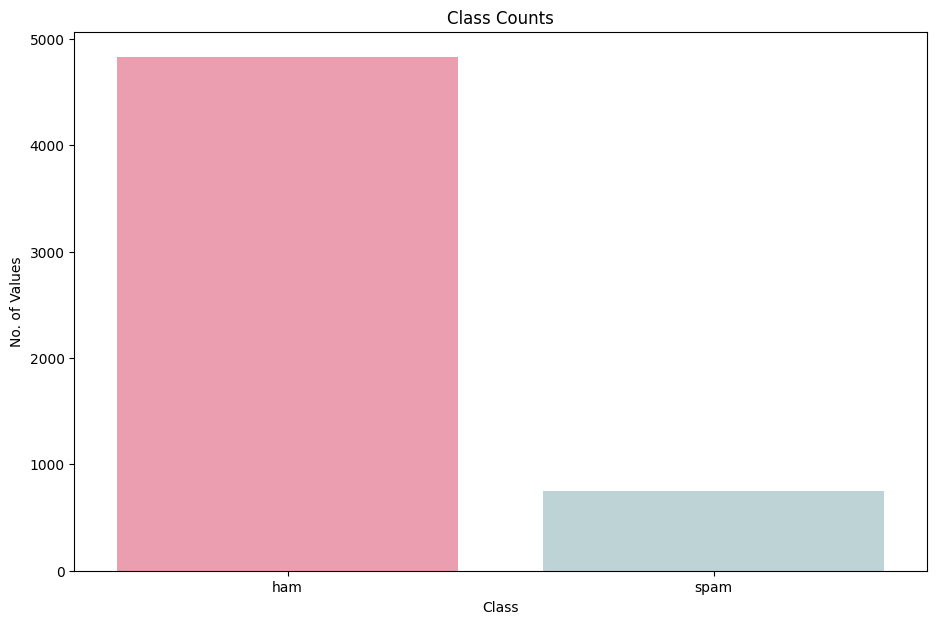

In [ ]:
plt.figure(figsize=(11,7))
chrt = sns.countplot(x= df["class"], palette= ["#F791A9", "#BAD6DA"])
chrt.set_title("Class Counts")
chrt.set_xlabel("Class")
chrt.set_ylabel("No. of Values")
plt.show()

This indicates that the messages that are legit are more than the spam messages in the dataset.

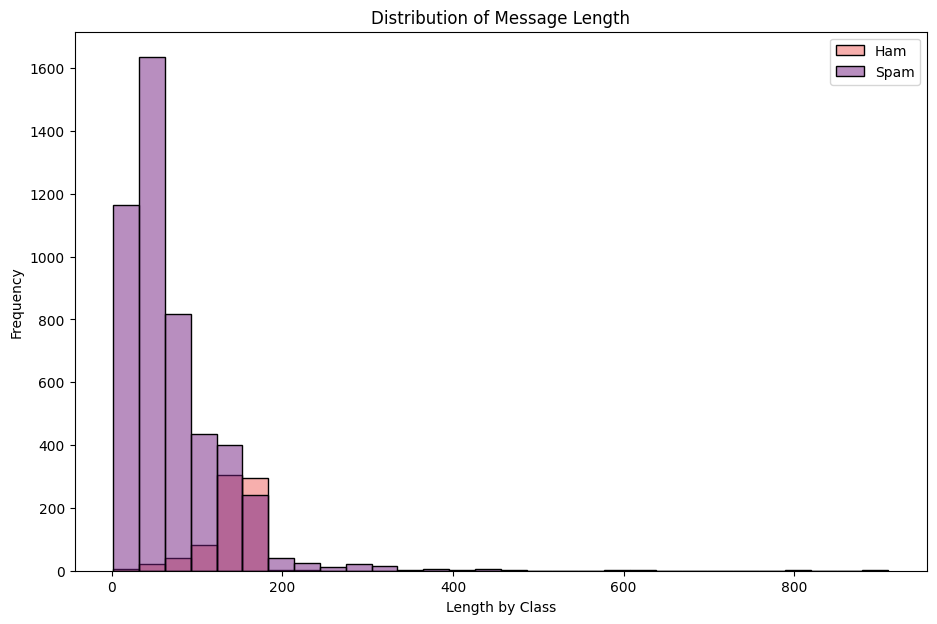

In [ ]:
df['msg_len'] = df['message'].apply(len)
plt.figure(figsize=(11,7))
sns.histplot(data=df, x='msg_len', hue='class', bins=30, palette='magma')
plt.title('Distribution of Message Length')
plt.xlabel('Length by Class')
plt.ylabel('Frequency')
plt.legend(['Ham', 'Spam'])
plt.show()

The chart shows that ham messages are longer by length than the spam messages.

In [ ]:
df['wc_map'] = df['class'].map({'ham': 0, 'spam': 1})

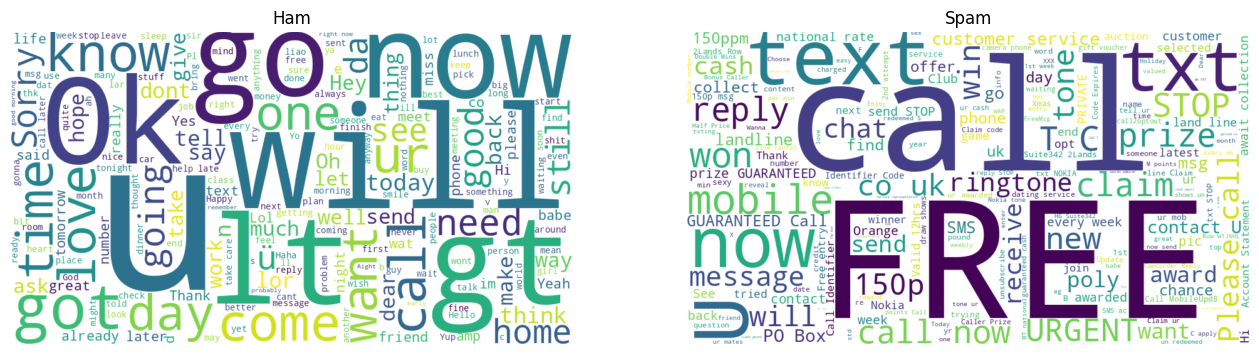

In [ ]:
hamW = ' '.join(df[df['wc_map'] == 0]['message'])
wcHam = WordCloud(width=900, height=500, background_color='white').generate(hamW)
spamW = ' '.join(df[df['wc_map'] == 1]['message'])
wcSpam = WordCloud(width=900, height=500, background_color='white').generate(spamW)

plt.figure(figsize=(16,8))

plt.subplot(1,2,1)
plt.imshow(wcHam, interpolation='bilinear')
plt.title('Ham')
plt.axis('off')

plt.subplot(1,2,2)
plt.imshow(wcSpam, interpolation='bilinear')
plt.title('Spam')
plt.axis('off')

plt.show()

It is apparent from the word clouds that the words "u", "will", "ok", "come", etc. are commonly found in ham messages while the words "call", "FREE", "now", "won", etc. are commonly found in spam messages.

# Text Preprocessing

In [ ]:
# save a copy of the message column before preprocessing
df['cleaned_message'] = df['message'].copy()

1. Cleaning text and handling punctuations with regex (regular expression)

In [ ]:
def clean_punc(msg):
  msg = re.sub(r'[^a-zA-Z\s]', '', msg)
  return msg
df['cleaned_message'] = df['cleaned_message'].apply(clean_punc)
df['cleaned_message'].head(3)

,cleaned_message
0,Go until jurong point crazy Available only in ...
1,Ok lar Joking wif u oni
2,Free entry in a wkly comp to win FA Cup final...


2. Case Normalization

In [ ]:
def case_norm(msg):
  msg = msg.lower()
  return msg
df['cleaned_message'] = df['cleaned_message'].apply(case_norm)
df['cleaned_message'].head(3)

,cleaned_message
0,go until jurong point crazy available only in ...
1,ok lar joking wif u oni
2,free entry in a wkly comp to win fa cup final...


3. Tokenization

In [ ]:
nltk.download('punkt')
nltk.download('punkt_tab')

def tokenizing(msg):
  words = nltk.word_tokenize(msg)
  return words
df['cleaned_message'] = df['cleaned_message'].apply(tokenizing)
df['cleaned_message'].head(3)

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


,cleaned_message
0,"[go, until, jurong, point, crazy, available, o..."
1,"[ok, lar, joking, wif, u, oni]"
2,"[free, entry, in, a, wkly, comp, to, win, fa, ..."


4. Stopword Removal

In [ ]:
nltk.download('stopwords')

def stpwrd_rmv(words):
  stp_word = set(stopwords.words('english'))
  filtered_text = [word for word in words if word not in stp_word]
  return filtered_text
df['cleaned_message'] = df['cleaned_message'].apply(stpwrd_rmv)
df['cleaned_message'].head(3)

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


,cleaned_message
0,"[go, jurong, point, crazy, available, bugis, n..."
1,"[ok, lar, joking, wif, u, oni]"
2,"[free, entry, wkly, comp, win, fa, cup, final,..."


5. Stemming

In [ ]:
stemmer = PorterStemmer()
def stem_word(words):
  words = [stemmer.stem(word) for word in words]
  return ' '.join(words)
df['cleaned_message'] = df['cleaned_message'].apply(stem_word)
df['cleaned_message'].head(3)

,cleaned_message
0,go jurong point crazi avail bugi n great world...
1,ok lar joke wif u oni
2,free entri wkli comp win fa cup final tkt st m...


In [ ]:
# comparison before and after preprocessing
pd.set_option('display.max_colwidth', None)
df[['message', 'cleaned_message']].head(10)

,message,cleaned_message
0,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...",go jurong point crazi avail bugi n great world la e buffet cine got amor wat
1,Ok lar... Joking wif u oni...,ok lar joke wif u oni
2,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's,free entri wkli comp win fa cup final tkt st may text fa receiv entri questionstd txt ratetc appli over
3,U dun say so early hor... U c already then say...,u dun say earli hor u c alreadi say
4,"Nah I don't think he goes to usf, he lives around here though",nah dont think goe usf live around though
5,"FreeMsg Hey there darling it's been 3 week's now and no word back! I'd like some fun you up for it still? Tb ok! XxX std chgs to send, £1.50 to rcv",freemsg hey darl week word back id like fun still tb ok xxx std chg send rcv
6,Even my brother is not like to speak with me. They treat me like aids patent.,even brother like speak treat like aid patent
7,As per your request 'Melle Melle (Oru Minnaminunginte Nurungu Vettam)' has been set as your callertune for all Callers. Press *9 to copy your friends Callertune,per request mell mell oru minnaminungint nurungu vettam set callertun caller press copi friend callertun
8,WINNER!! As a valued network customer you have been selected to receivea £900 prize reward! To claim call 09061701461. Claim code KL341. Valid 12 hours only.,winner valu network custom select receivea prize reward claim call claim code kl valid hour
9,Had your mobile 11 months or more? U R entitled to Update to the latest colour mobiles with camera for Free! Call The Mobile Update Co FREE on 08002986030,mobil month u r entitl updat latest colour mobil camera free call mobil updat co free


The table shows how the messages after preprocessing are now consistent and free from noise and punctuation.

# Vector Representation and Similarity (TF-IDF + Cosine Similarity)

In this section, each preprocessed SMS message is converted into a numeric vector using **TF-IDF**, and **cosine similarity** is used to measure how similar two messages are.

- **TF (Term Frequency):** how often a word appears in a message.
- **IDF (Inverse Document Frequency):** gives a higher weight to words that are rare across all messages, and a lower weight to very common words.
- **TF-IDF = TF × IDF**, so the words that best describe a message get the highest scores.
- **Cosine similarity** measures the angle between two TF-IDF vectors. A score of **1** means the messages use the same important words, and **0** means they share no words.

1. Building the TF-IDF Representation

In [ ]:
tfidf = TfidfVectorizer()
X_tfidf = tfidf.fit_transform(df['cleaned_message'])

print('TF-IDF matrix shape:', X_tfidf.shape)
print('Number of messages :', X_tfidf.shape[0])
print('Vocabulary size    :', X_tfidf.shape[1])
sparsity = 1 - (X_tfidf.nnz / (X_tfidf.shape[0] * X_tfidf.shape[1]))
print(f'Sparsity           : {sparsity:.2%}')

# masks to select each class (used in the next parts)
spam_mask = (df['class'] == 'spam').values
ham_mask = (df['class'] == 'ham').values

TF-IDF matrix shape: (5572, 7139)
Number of messages : 5572
Vocabulary size    : 7139
Sparsity           : 99.89%


The matrix has one row per message and one column per unique word. Most values are zero (very sparse), because each SMS is short and only uses a few words from the full vocabulary.

In [ ]:
# TF-IDF weights of the words in one example message
feature_names = tfidf.get_feature_names_out()
idx = 2
row = X_tfidf[idx].toarray().flatten()
nonzero = row.nonzero()[0]

example = pd.DataFrame({'word': feature_names[nonzero], 'tfidf_weight': row[nonzero]})
example = example.sort_values('tfidf_weight', ascending=False).reset_index(drop=True)

print('Original message:', df['message'][idx])
print('Cleaned message :', df['cleaned_message'][idx])
example

Original message: Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's
Cleaned message : free entri wkli comp win fa cup final tkt st may text fa receiv entri questionstd txt ratetc appli over


,word,tfidf_weight
0,fa,0.502122
1,entri,0.384796
2,ratetc,0.251061
3,questionstd,0.251061
4,over,0.251061
5,tkt,0.236021
6,cup,0.212806
7,comp,0.210244
8,wkli,0.203675
9,final,0.179581


Words that are rare in the dataset (such as "fa" and "entri", from the football competition) get higher weights, while common words get lower weights. This shows how TF-IDF highlights the words that make a message distinctive.

2. Most Important Words in Each Class

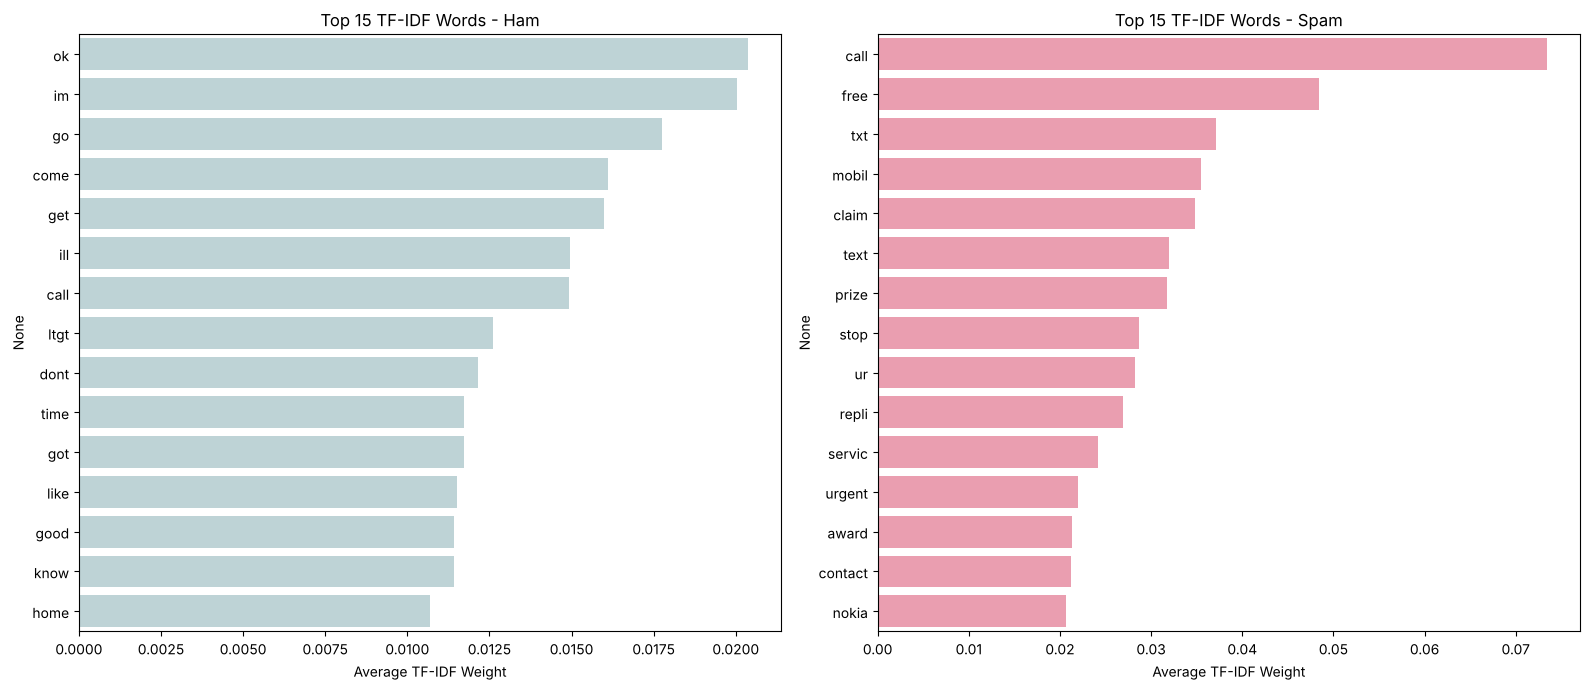

In [ ]:
spam_mean = np.asarray(X_tfidf[spam_mask].mean(axis=0)).flatten()
ham_mean = np.asarray(X_tfidf[ham_mask].mean(axis=0)).flatten()

top_spam = pd.Series(spam_mean, index=feature_names).sort_values(ascending=False).head(15)
top_ham = pd.Series(ham_mean, index=feature_names).sort_values(ascending=False).head(15)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

sns.barplot(x=top_ham.values, y=top_ham.index, ax=axes[0], color='#BAD6DA')
axes[0].set_title('Top 15 TF-IDF Words - Ham')
axes[0].set_xlabel('Average TF-IDF Weight')

sns.barplot(x=top_spam.values, y=top_spam.index, ax=axes[1], color='#F791A9')
axes[1].set_title('Top 15 TF-IDF Words - Spam')
axes[1].set_xlabel('Average TF-IDF Weight')

plt.tight_layout()
plt.show()

Spam messages are dominated by words like "call", "free", "txt", "claim", "prize" and "mobil", which relate to offers and prizes. Ham messages are dominated by everyday conversation words like "ok", "go", "come", "time" and "home". This confirms that TF-IDF captures the vocabulary that separates the two classes.